In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import ast
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import scipy.stats as stats

from scipy import spatial

from load_data import get_object_names, DATA_ROOT, load_all
objects = get_object_names()

tax_colour_dict = {'bee':'gold', 
                    'branch': 'sienna',
                   'katydid': 'olive',
                   'ladybug': 'crimson',
                   'leaf': 'forestgreen',
                    'phyllium': 'lime',
                   'stick_insect': 'lightcoral', 
                   'tree': 'saddlebrown', 
                   'tree_trunk':  'saddlebrown',
                   'wasp':'darkgoldenrod'}

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }


sns.set_theme(style="whitegrid", context='notebook')


matplotlib.rcParams['font.sans-serif'] = "Arial"
# Then, "ALWAYS use sans-serif fonts"
matplotlib.rcParams['font.family'] = "sans-serif"

action: 18 images
greebles: 18 images
taxonomic: 18 images


In [2]:
df = pd.read_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30.csv')

In [3]:
# convert saved embedding as text to a numpy array
df['embedding'] = df['embedding'].apply(lambda x: np.array(ast.literal_eval(x)))
df['n_triplets'] = df['triplets'].apply(lambda x: len(x))

In [4]:
triplet_df = load_all() #load data

In [5]:
#change P1 to O5 for consistent naming
observers = []
for row in triplet_df.iterrows():
    o = row[1].observer
    s = row[1].session
    if o != "P1":
        observers.append(o)
    else:
        if s == "1a" or s == "2a" or s == "1b" or s == "2b": # only for the sessions that matter
            observers.append("O5")
        else:
            observers.append(o)
triplet_df.observer = observers 

In [6]:
triplet_df = triplet_df[(triplet_df['observer']=='O1') | (triplet_df['observer']=='O2') | 
                        (triplet_df['observer']=='O3') | (triplet_df['observer']=='O4') | 
                        (triplet_df['observer']=='O5')]

In [7]:
def get_agg_embedding_obs_task_imset(observer, im_set, task, df):
    d = df[(df['observer']==observer) & (df['image_set']==im_set) & (df['task']==task)]
    assert(len(d)==1)
    return d.iloc[0]['embedding']


def calculate_triplet_correct(embedding, triplets):
    
    anchor = embedding[triplets[0], :]
    positive = embedding[triplets[1], :]
    negative = embedding[triplets[2], :]

    # calculates euclidean distance with np.linalg.norm
    ncorrect = np.sum(np.linalg.norm(anchor - positive)< np.linalg.norm(anchor - negative))

    return ncorrect



# Triplet accuracy for triplets repeated more or less frequently
Is the triplet accuracy similar for 3 and 6 repetitions?

In [8]:
trip = [8,2,3]
trip_sorted = trip[1:].copy()
trip_sorted.sort()
tup = tuple(trip[:1]+trip_sorted)

In [9]:
trip_reps = {}
for participant in ['O1','O2','O3','O4','O5']:
    participant_df = triplet_df[triplet_df.observer == participant]
    classic_p_df = participant_df[participant_df.task == "classic"]
    par_n_reps = {}
    all_refs = []
    for image_set in ["action", "greebles","taxonomic"]: # for all image sets individually
        imset_c_p_df = classic_p_df[classic_p_df.image_set == image_set]
        embedding_agg = get_agg_embedding_obs_task_imset(participant, image_set, "classic", df)
        triplets = {}
        for row in imset_c_p_df.iterrows():
            trips = row[1].embedding_ready_triplets
            for trip in trips:
                n_correct = calculate_triplet_correct(embedding_agg, trip)
                trip_sorted = trip[1:].copy()
                trip_sorted.sort()
                tup = (trip[0],trip_sorted[0],trip_sorted[1])
                try:
                    triplets[tup] = [triplets[tup][0]+1, triplets[tup][1]+n_correct]
                except:
                    triplets[tup] = [1, n_correct]
        trip_reps[(participant, image_set)] = triplets

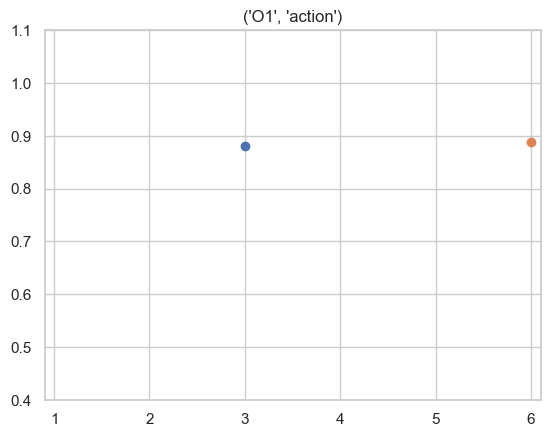

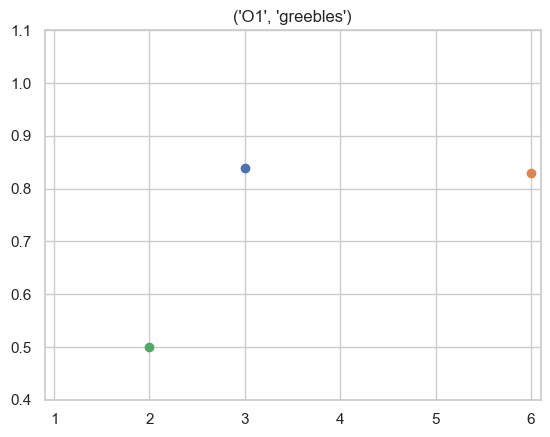

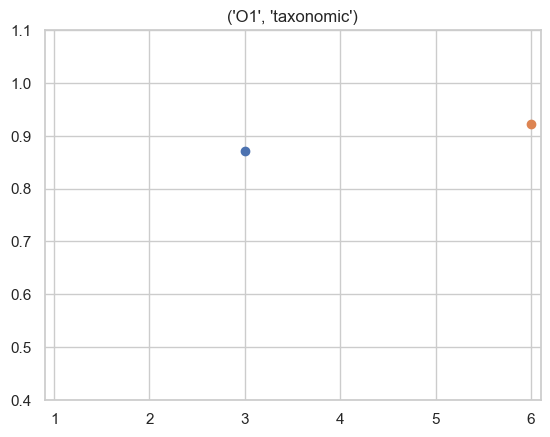

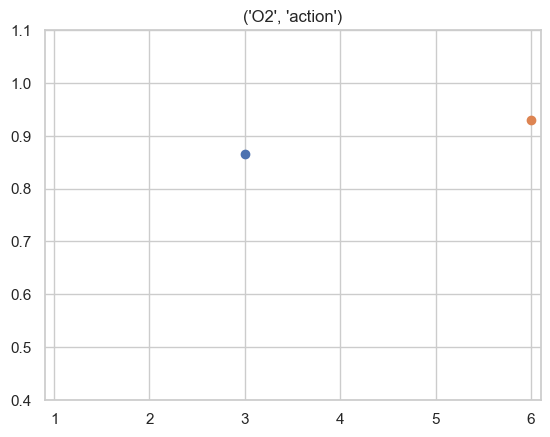

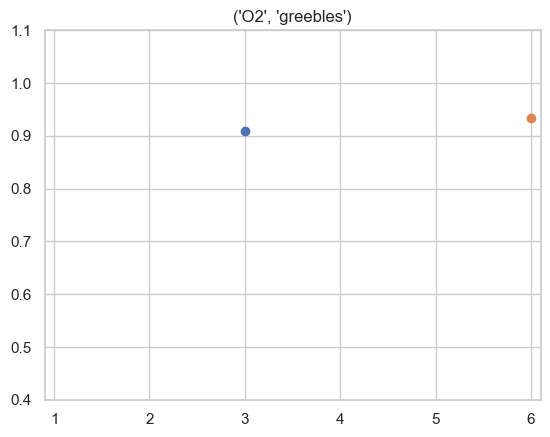

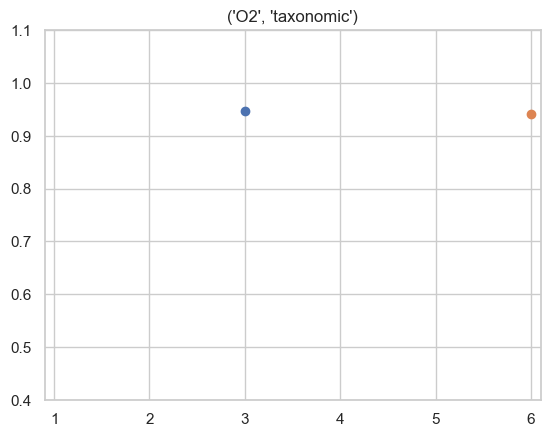

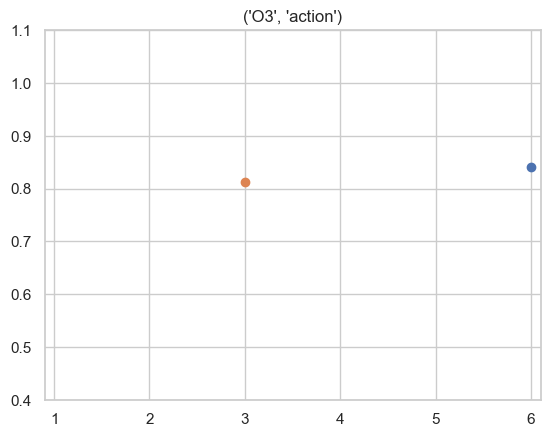

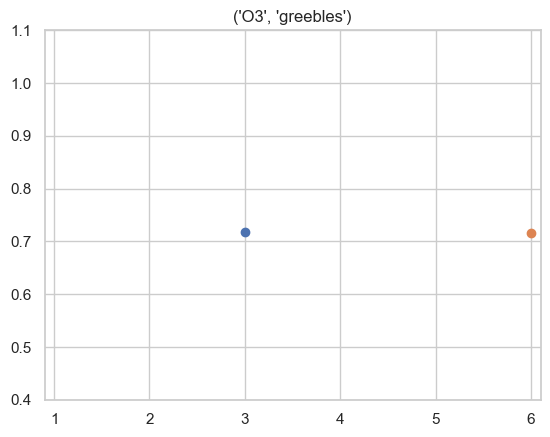

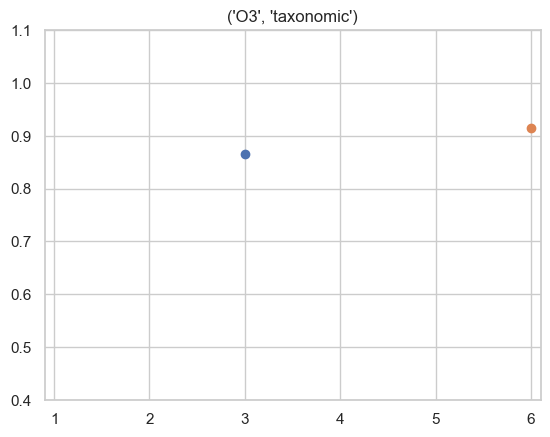

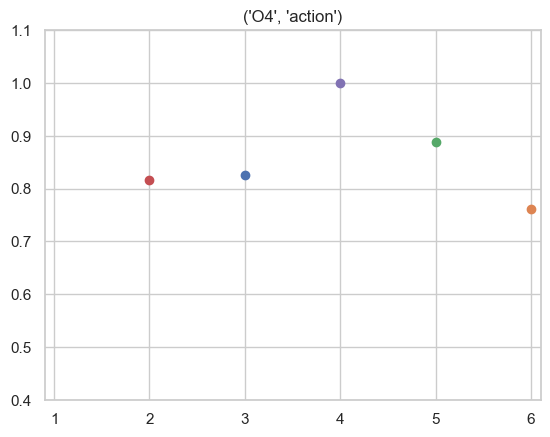

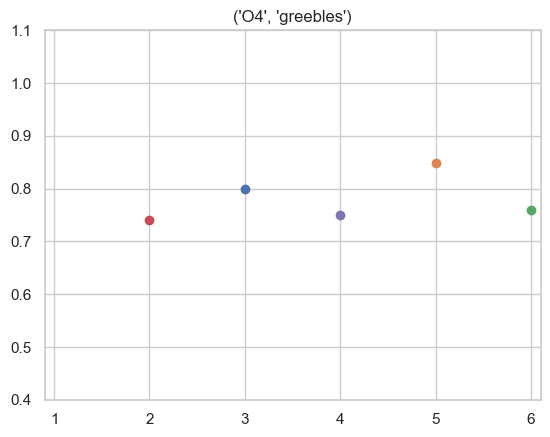

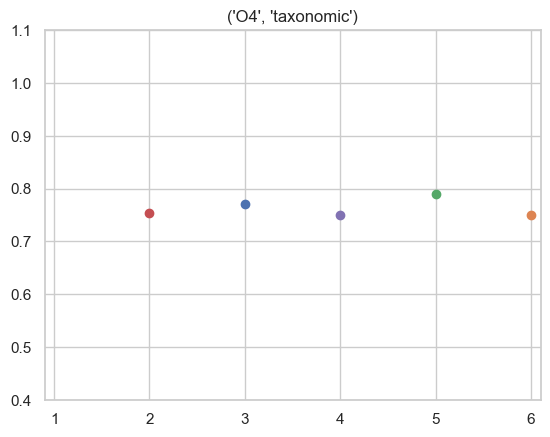

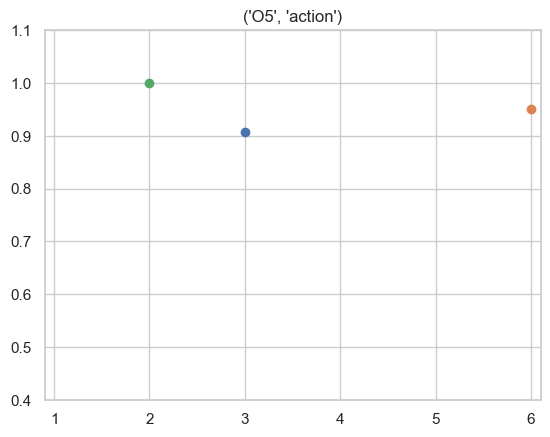

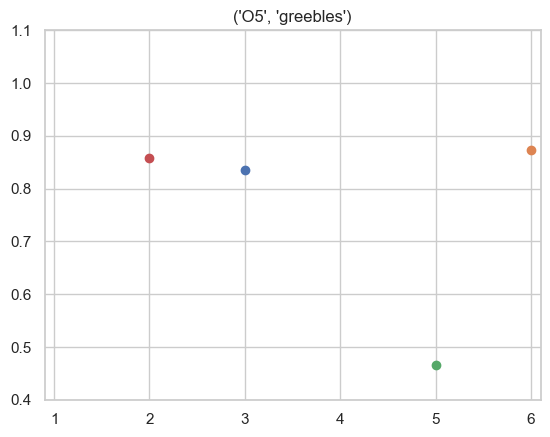

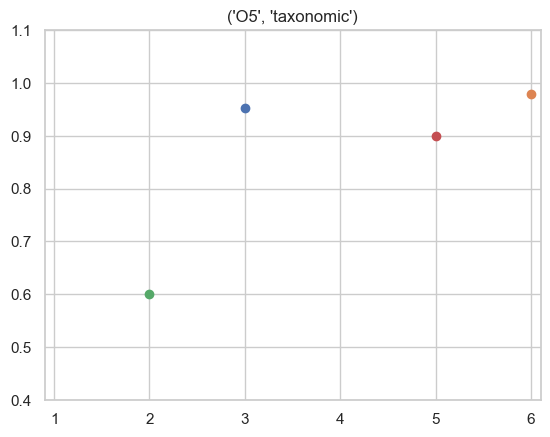

In [10]:
across_pars_rep_errors = {1:[],2:[],3:[],4:[],5:[],6:[]}
nr_triplets = {1:0,2:0,3:0,4:0,5:0,6:0}
for par_imset in trip_reps:
    triplets = trip_reps[par_imset]
    rep_errors = {}
    for trip in triplets:
        nreps = triplets[trip][0]
        ncorr = triplets[trip][1]
        try:
            rep_errors[nreps] = [rep_errors[nreps][0]+nreps, rep_errors[nreps][1]+ncorr]
        except:
            rep_errors[nreps] = [nreps, ncorr]
    
    for nreps in rep_errors:
        if rep_errors[nreps][1]>0:
            across_pars_rep_errors[nreps].append(rep_errors[nreps][1]/rep_errors[nreps][0])
            nr_triplets[nreps] = nr_triplets[nreps] + (rep_errors[nreps][0]/nreps)
        plt.scatter(nreps, rep_errors[nreps][1]/rep_errors[nreps][0])
    plt.title(par_imset)
    plt.ylim(0.4,1.1)
    plt.xlim(0.9,6.1)
    plt.xticks([1,2,3,4,5,6])
    plt.show()

In [11]:
nr_triplets

{1: 0, 2: 397.0, 3: 7212.0, 4: 7.0, 5: 61.0, 6: 627.0}

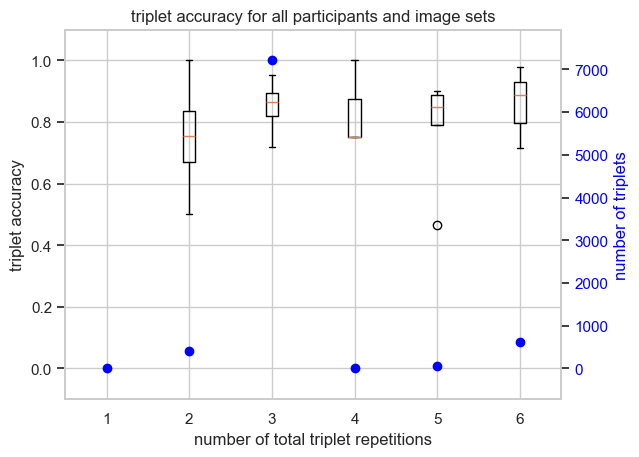

In [12]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.set_ylim(-0.1,1.1)
ax2.set_ylim(-721.2,7212+721.2)
for nrep in across_pars_rep_errors:
    ax1.boxplot(across_pars_rep_errors[nrep], positions=[nrep])
    ax2.scatter(nrep,nr_triplets[nrep],c="blue")
plt.title("triplet accuracy for all participants and image sets")
ax1.set_xlabel("number of total triplet repetitions")
ax2.set_ylabel("number of triplets",color="blue")
ax2.tick_params(labelcolor="blue")
ax2.grid(False)
ax1.set_ylabel("triplet accuracy");

## T-Test
Is there a difference between the accuracy for the triplets of an image set and participant that are repeated three times and those that are repeated six times?

In [13]:
stats.ttest_rel(np.array(across_pars_rep_errors[3]),np.array(across_pars_rep_errors[6]))

TtestResult(statistic=-1.3511156516380012, pvalue=0.19809041153334056, df=14)

# Triplet accuracy in the repetitions
Is the triplet accuracy similar the first, second, third, ... time a triplet shown?

In [14]:
reps_corr = {}
for participant in ['O1','O2','O3','O4','O5']:
    participant_df = triplet_df[triplet_df.observer == participant]
    classic_p_df = participant_df[participant_df.task == "classic"]
    par_n_reps = {}
    all_refs = []
    for image_set in ["action", "greebles","taxonomic"]: # for all image sets individually
        imset_c_p_df = classic_p_df[classic_p_df.image_set == image_set]
        embedding_agg = get_agg_embedding_obs_task_imset(participant, image_set, "classic", df)
        imset_c_p_df = imset_c_p_df.sort_values("date")
        triplets = {}
        for row in imset_c_p_df.iterrows():
            trips = row[1].embedding_ready_triplets
            for trip in trips:
                n_correct = calculate_triplet_correct(embedding_agg, trip)
                trip_sorted = trip[1:].copy()
                trip_sorted.sort()
                tup = (trip[0],trip_sorted[0],trip_sorted[1])
                try:
                    triplets[tup].append(n_correct)
                except:
                    triplets[tup] = [n_correct]
        reps_corr [(participant, image_set)] = triplets

In [15]:
nreps = {}
corr_nreps = {}
for par_im in reps_corr:
    par_im_trips = reps_corr[par_im]
    for trip in par_im_trips:
        ncorr = par_im_trips[trip]
        for rep in range(len(ncorr)):
            try:
                nreps[rep+1] = nreps[rep+1]+1
                corr_nreps[rep+1] = corr_nreps[rep+1]+ncorr[rep]
            except:
                nreps[rep+1] = 1
                corr_nreps[rep+1] = ncorr[rep]           

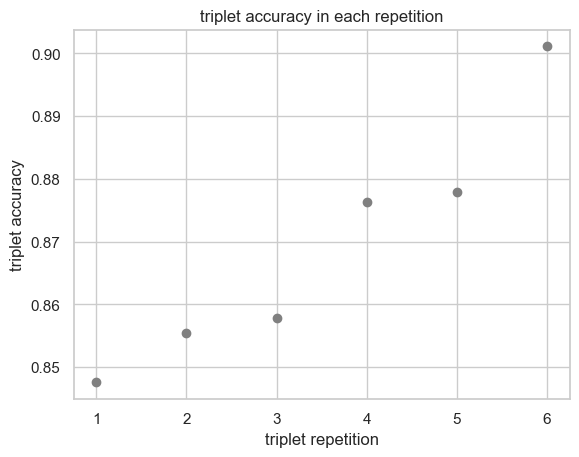

In [16]:
for rep in nreps:
    plt.scatter(rep,corr_nreps[rep]/nreps[rep], color = "grey")
plt.title("triplet accuracy in each repetition")
plt.xlabel("triplet repetition")
plt.ylabel("triplet accuracy");

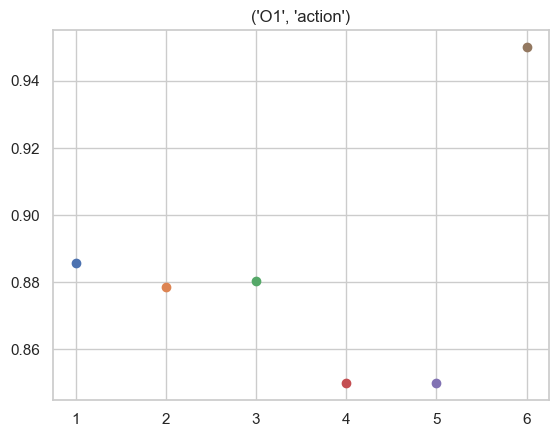

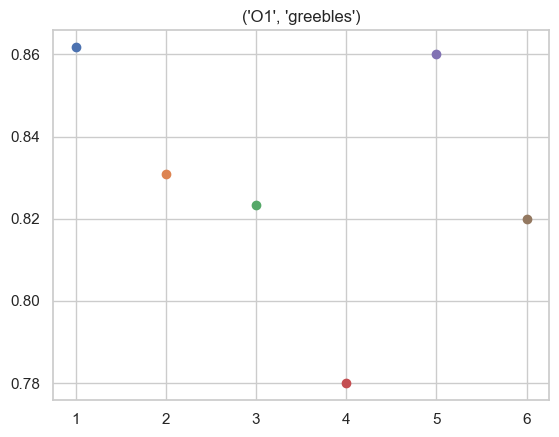

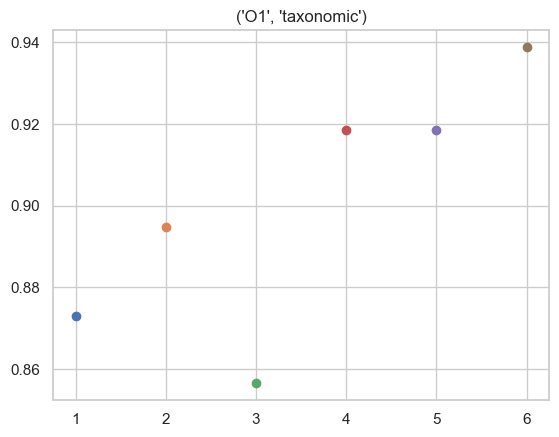

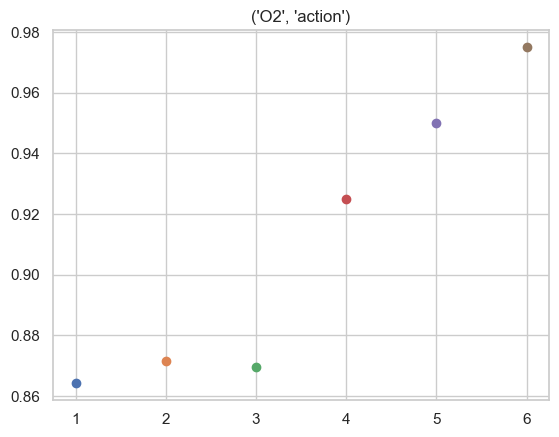

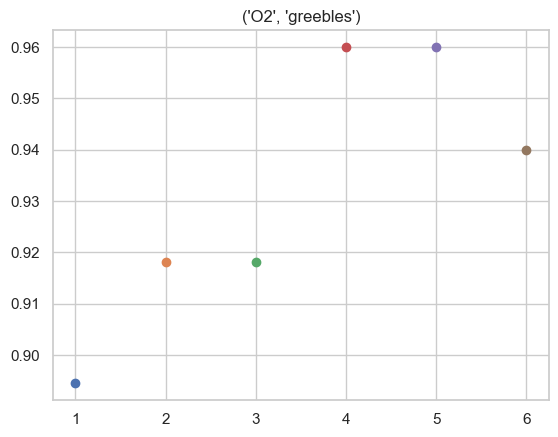

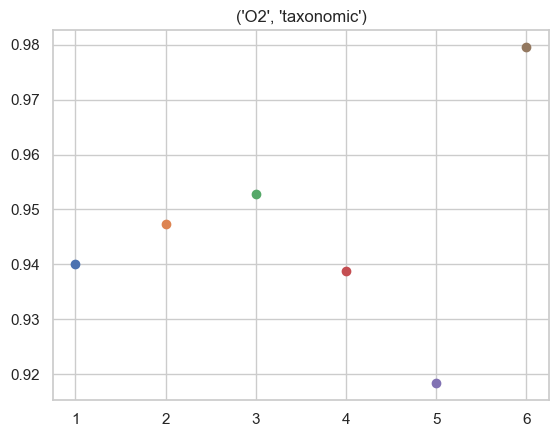

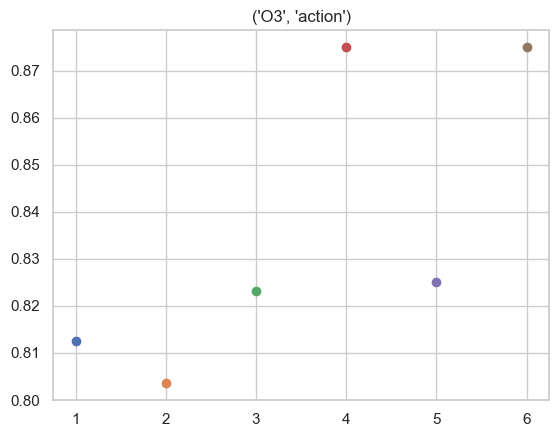

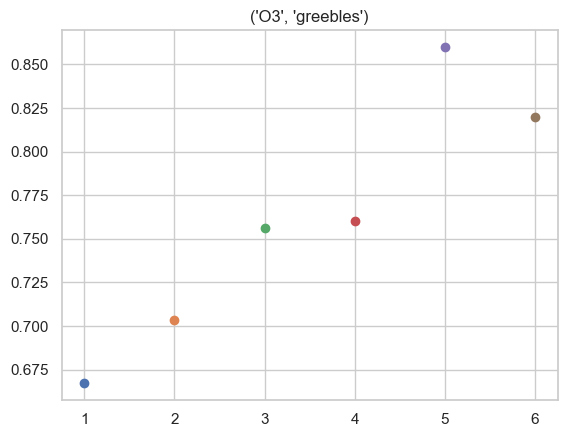

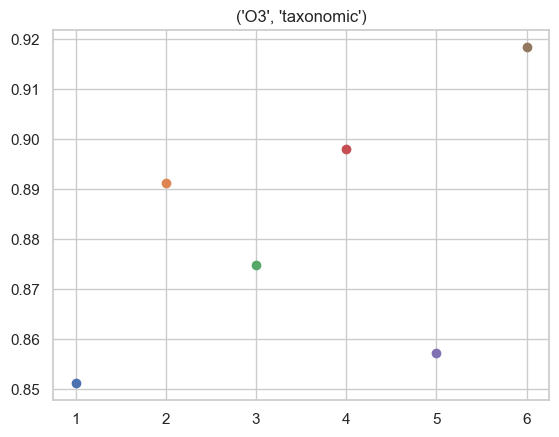

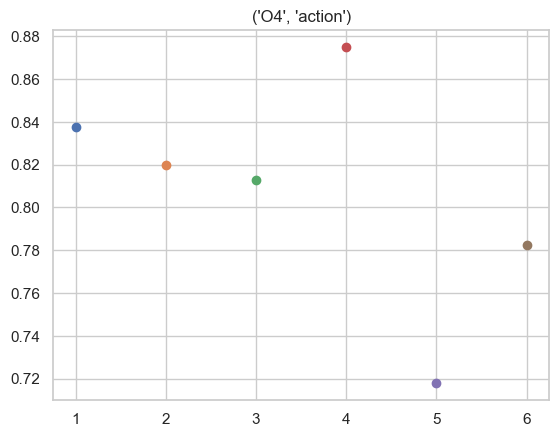

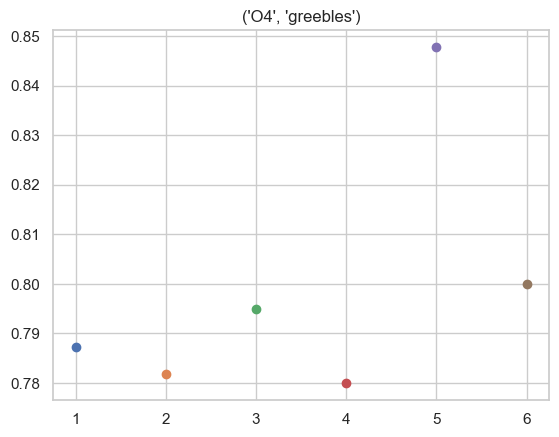

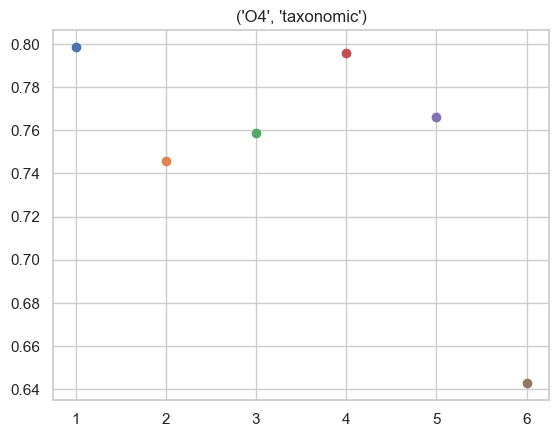

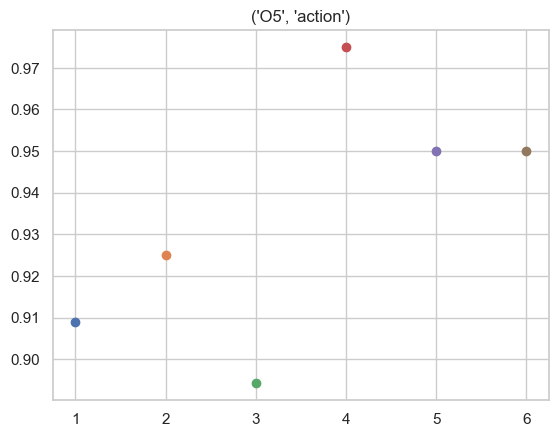

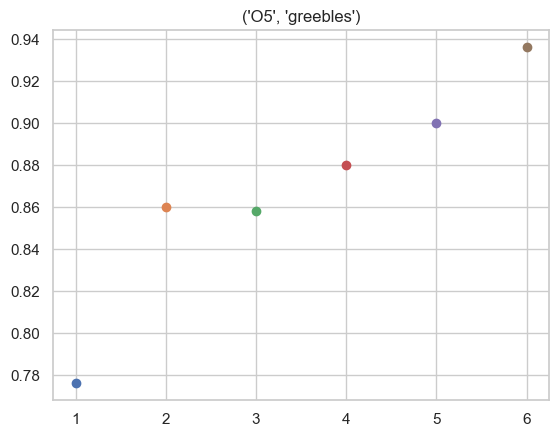

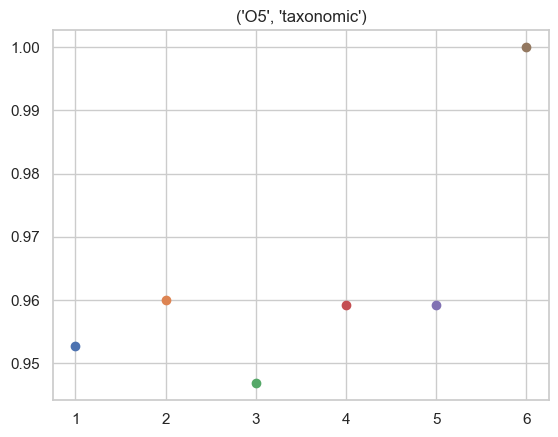

In [17]:
repetition = []
percent_correct = []
for par_im in reps_corr:
    par_im_trips = reps_corr[par_im]
    nreps = {}
    corr_nreps = {}
    for trip in par_im_trips:
        ncorr = par_im_trips[trip]
        for rep in range(len(ncorr)):
            try:
                nreps[rep+1] = nreps[rep+1]+1
                corr_nreps[rep+1] = corr_nreps[rep+1]+ncorr[rep]
            except:
                nreps[rep+1] = 1
                corr_nreps[rep+1] = ncorr[rep]
    for rep in nreps:
        plt.scatter(rep,corr_nreps[rep]/nreps[rep])
        repetition.append(rep)
        percent_correct.append(corr_nreps[rep]/nreps[rep])
    plt.title(par_im)
    plt.show()

In [18]:
rep_percent = {}

for rep, perc in zip(repetition, percent_correct):
    if rep not in rep_percent:
        rep_percent[rep] = []
    rep_percent[rep].append(perc)

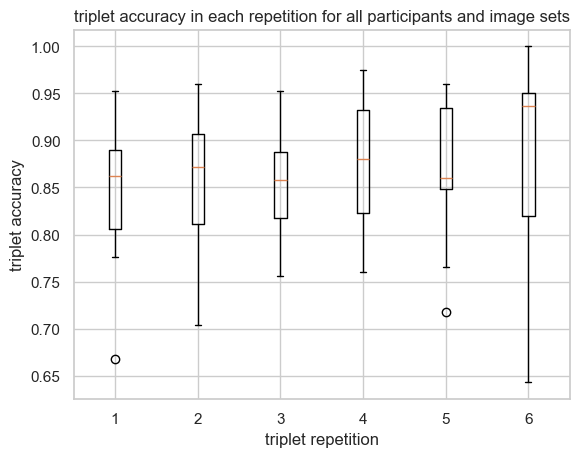

In [19]:
#plt.scatter(repetition,percent_correct)
for rep in rep_percent:
    plt.boxplot(rep_percent[rep], positions=[rep])
plt.title("triplet accuracy in each repetition for all participants and image sets")
plt.xlabel("triplet repetition")
plt.ylabel("triplet accuracy");

# Triplet accuracy over reference appearances
Do triplets which include images that are used as the reference more frequently have higher triplet accuracy?

In [20]:
nimage = {}
image_acc = {}
for participant in ['O1','O2','O3','O4','O5']:
    participant_df = triplet_df[triplet_df.observer == participant]
    classic_p_df = participant_df[participant_df.task == "classic"]
    parim_nimage = {}
    parim_image_acc = {}
    for image_set in ["action", "greebles","taxonomic"]: # for all image sets individually
        imset_c_p_df = classic_p_df[classic_p_df.image_set == image_set]
        embedding_agg = get_agg_embedding_obs_task_imset(participant, image_set, "classic", df)
        for row in imset_c_p_df.iterrows():
            trips = row[1].embedding_ready_triplets
            for trip in trips:
                correct = calculate_triplet_correct(embedding_agg, trip)
                for image in trip:
                    if image in parim_image_acc.keys():
                        parim_image_acc[image] = parim_image_acc[image] + correct
                        parim_nimage[image] = parim_nimage[image] + 1
                    else:
                        parim_image_acc[image] = correct
                        parim_nimage[image] = 1
        for image in parim_image_acc:
            if image in image_acc.keys():
                image_acc[image].append(parim_image_acc[image]/parim_nimage[image])
                nimage[image] = nimage[image] + parim_nimage[image]
            else:
                image_acc[image] = [parim_image_acc[image]/parim_nimage[image]]
                nimage[image] = parim_nimage[image]                   

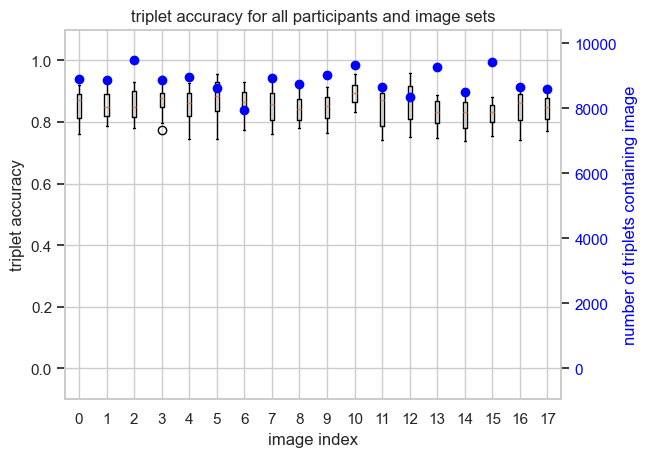

In [21]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.set_ylim(-0.1,1.1)
ax2.set_ylim(-947.5,9475+947.5)
for image in image_acc:
    ax1.boxplot(image_acc[image], positions=[image])
    ax2.scatter(image,nimage[image],c="blue")
plt.title("triplet accuracy for all participants and image sets")
ax1.set_xlabel("image index")
ax2.set_ylabel("number of triplets containing image",color="blue")
ax2.tick_params(labelcolor="blue")
ax2.grid(False)
ax1.set_ylabel("triplet accuracy");

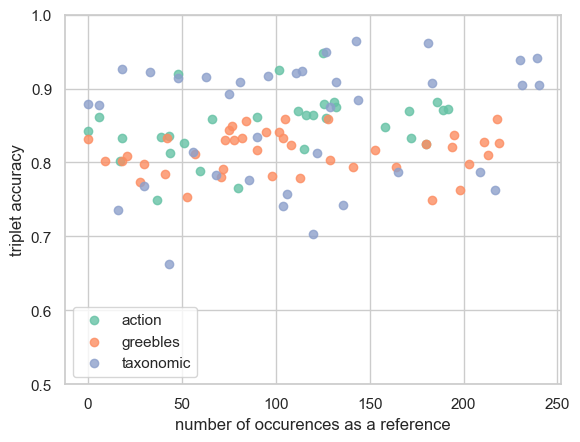

In [22]:
fig, ax1 = plt.subplots()
nr_triplets = {}
ref_occ_acc = {}
for image_set in ["action", "greebles","taxonomic"]: # for all image sets individually
    classic_df = triplet_df[triplet_df.task == "classic"]
    imset_df = classic_df[classic_df.image_set == image_set]
    imset_ref_occ_acc = {}
    for participant in ['O1','O2','O3','O4','O5']:
        imset_c_p_df = imset_df[imset_df.observer == participant]
        embedding_agg = get_agg_embedding_obs_task_imset(participant, image_set, "classic", df)
        parim_nimage = {}
        parim_image_acc = {}
        ref_occs={17:0}
        for row in imset_c_p_df.iterrows():
            trips = row[1].embedding_ready_triplets
            for trip in trips:
                correct = calculate_triplet_correct(embedding_agg, trip)
                #count occurences of images as reference
                if trip[0] in ref_occs.keys():
                    ref_occs[trip[0]] = ref_occs[trip[0]] + 1
                else:
                    ref_occs[trip[0]] = 1
                # for each image in the triplet count appearances and correct answers
                for image in trip:
                    if image in parim_image_acc.keys():
                        parim_image_acc[image] = parim_image_acc[image] + correct
                        parim_nimage[image] = parim_nimage[image] + 1
                    else:
                        parim_image_acc[image] = correct
                        parim_nimage[image] = 1
        for image in parim_image_acc:
            if ref_occs[image] in ref_occ_acc.keys():
                ref_occ_acc[ref_occs[image]].append(parim_image_acc[image]/parim_nimage[image])
                nr_triplets[ref_occs[image]] = nr_triplets[ref_occs[image]] + parim_nimage[image]
            else: 
                ref_occ_acc[ref_occs[image]] = [parim_image_acc[image]/parim_nimage[image]]
                nr_triplets[ref_occs[image]] =  parim_nimage[image]

            if ref_occs[image] in imset_ref_occ_acc.keys():
                imset_ref_occ_acc[ref_occs[image]].append(parim_image_acc[image]/parim_nimage[image])
            else:
                imset_ref_occ_acc[ref_occs[image]] = [parim_image_acc[image]/parim_nimage[image]]

    #plot individual for each image set
    ax1.set_ylim(0.5,1)
    for ref_occ in imset_ref_occ_acc:
        ax1.scatter(ref_occ, np.mean(imset_ref_occ_acc[ref_occ]), color = palette_imset[image_set], alpha=.8)
    ax1.set_xlabel("number of occurences as a reference")
    ax1.set_ylabel("triplet accuracy")
    ax1.scatter([],[], color = palette_imset[image_set], alpha=.8, label= image_set)
plt.legend();

# save plot as pdf
fig.savefig('../plots/triplet_accuracy_over_reference_occurrence.pdf', bbox_inches='tight')

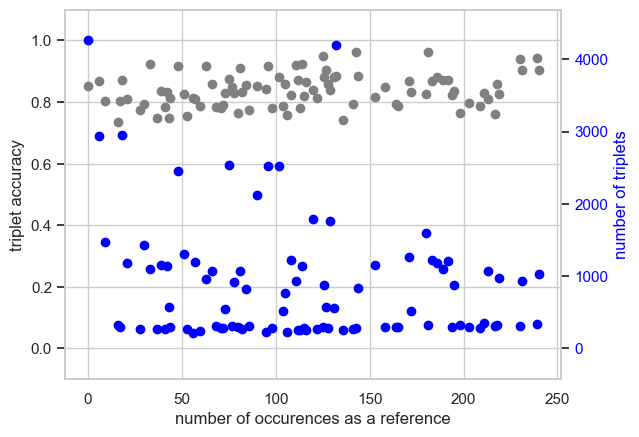

In [23]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.set_ylim(-0.1,1.1)
ax2.set_ylim(-426,4260+426)
for ref_occ in ref_occ_acc:
    ax1.scatter(ref_occ, np.mean(ref_occ_acc[ref_occ]), color = "grey")
    ax2.scatter(ref_occ,nr_triplets[ref_occ],c="blue")
#plt.title("triplet accuracy for all participants and image sets")
ax1.set_xlabel("number of occurences as a reference")
ax2.set_ylabel("number of triplets",color="blue")
ax2.tick_params(labelcolor="blue")
ax2.grid(False)
ax1.set_ylabel("triplet accuracy");

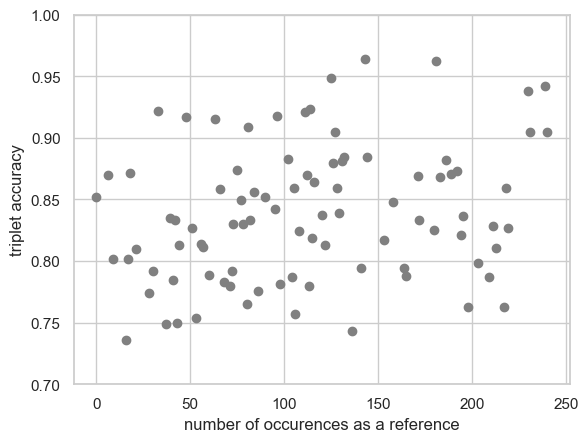

In [24]:
fig, ax1 = plt.subplots()
#ax2 = ax1.twinx()
ax1.set_ylim(0.7,1)
#ax2.set_ylim(-426,4260+426)
for ref_occ in ref_occ_acc:
    ax1.scatter(ref_occ, np.mean(ref_occ_acc[ref_occ]), color = "grey")
    #ax2.scatter(ref_occ,nr_triplets[ref_occ],c="blue")
#plt.title("triplet accuracy for all participants and image sets")
ax1.set_xlabel("number of occurences as a reference")
#ax2.set_ylabel("number of triplets",color="blue")
#ax2.tick_params(labelcolor="blue")
#ax2.grid(False)
ax1.set_ylabel("triplet accuracy");

## Appearances of each image as reference (Supplementary Table S3)

Sessions 1 - 9 of one shuffle (`a`) hold every triplet of the design once. In the classic task the
reference is the middle image; count how often each image index is the reference, per image set.

In [25]:
condition_files = sorted((DATA_ROOT / 'experiment/conditions').glob('triplets_3x18_session[1-9]a.csv'))
design = pd.concat([pd.read_csv(f) for f in condition_files], ignore_index=True)
reference_counts = design.groupby(['image_set', 'middle_index']).size().unstack('image_set').reindex(range(18), fill_value=0)
print(reference_counts)
print('triplets per image set:', reference_counts.sum().to_dict())

image_set     action  greebles  taxonomic
middle_index                             
0                272       272        272
1                256       256        256
2                240       240        240
3                224       224        224
4                208       208        208
5                192       192        192
6                176       176        176
7                160       160        160
8                144       144        144
9                128       128        128
10               112       112        112
11                96        96         96
12                80        80         80
13                64        64         64
14                48        48         48
15                32        32         32
16                16        16         16
17                 0         0          0
triplets per image set: {'action': 2448, 'greebles': 2448, 'taxonomic': 2448}
